# Transformada rápida
El objetivo de este script es tomar los pulsos registrados y retornar una transformada rápida de furier para

In [1]:
FRECUENCIA=360

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

def graficar_espectrograma(puntos, fs, nperseg=FRECUENCIA, titulo='Espectrograma de Frecuencias'):
    """
    Calcula y grafica el espectrograma de una colección de puntos (señal en el tiempo).

    Argumentos:
    puntos (array_like): La colección de puntos de la señal (onda).
    fs (float): La frecuencia de muestreo en Hertz (muestras por segundo).
    nperseg (int, opcional): Longitud de cada segmento para la FFT. 
                            Mayor valor = mejor resolución de frecuencia, 
                            peor resolución de tiempo. Por defecto 256.
    titulo (str, opcional): Título de la gráfica.
    """
    
    # Asegurar que los datos sean un arreglo de numpy
    x = np.asarray(puntos)
    
    # 1. Calcular la STFT (Short-Time Fourier Transform) para obtener el espectrograma
    # f: Arreglo de frecuencias calculadas (Eje Y)
    # t: Arreglo de tiempos calculados (Eje X)
    # Sxx: Densidad espectral de potencia (valores de intensidad/color)
    f, t, Sxx = signal.spectrogram(x, fs=fs, nperseg=nperseg)

    # 2. Convertir la intensidad a Decibeles (dB)
    # Esto es crucial porque el oído humano y muchas señales varían logarítmicamente.
    # Usamos np.log10(Sxx + eps) para evitar logaritmo de cero si hay silencio.
    Sxx_log = 10 * np.log10(Sxx + 1e-10)

    # 3. Graficar
    plt.figure(figsize=(10, 6))
    
    # pcolormesh crea una cuadrícula de color basada en t, f, y la intensidad en dB
    # cmap='viridis' o cmap='magma' son buenas opciones de color
    plt.pcolormesh(t, f, Sxx_log, shading='gouraud', cmap='viridis')
    
    plt.title(titulo)
    plt.ylabel('Frecuencia (Hz)')
    plt.xlabel('Tiempo (s)')
    plt.colorbar(label='Potencia/Frecuencia (dB/Hz)')
    plt.tight_layout()
    plt.show()

In [3]:
from scipy import signal
import numpy as np

def obtener_matriz_espectrograma(puntos, fs, nperseg=48):
    """
    Calcula el espectrograma y retorna la matriz estandarizada en decibeles.
    """
    x = np.asarray(puntos)
    
    # Calcular la STFT
    f, t, Sxx = signal.spectrogram(x, fs=fs, nperseg=nperseg)
    
    # Convertir a decibeles
    Sxx_log = 10 * np.log10(Sxx + 1e-10)
    
    # Normalizar entre 0 y 1 (Crucial para entrenar la CNN)
    Sxx_norm = (Sxx_log - np.min(Sxx_log)) / (np.max(Sxx_log) - np.min(Sxx_log))
    
    return Sxx_norm

In [4]:
import matplotlib.pyplot as plt
import numpy as np
import wfdb
import pandas as pd
from scipy import signal

# --- FUNCIONES PREVIAS ---

def extraer_latido_asimetrico(voltaje_total, df_picos, indice_latido, fs=360, tiempo_ventana=0.75):
    """
    Extrae una ventana asimétrica (35% - 65%) centrada en el pico R.
    """
    muestras_totales = int(tiempo_ventana * fs)
    muestras_izq = int(muestras_totales * 0.35)
    muestras_der = muestras_totales - muestras_izq
    
    centro_r = int(df_picos['Pulsos'].iloc[indice_latido])
    
    inicio = centro_r - muestras_izq
    fin = centro_r + muestras_der
    
    if inicio < 0 or fin > len(voltaje_total):
        print(f"Advertencia: El latido {indice_latido} está demasiado cerca del borde y se ignorará.")
        return None
        
    return voltaje_total[inicio:fin]

def graficar_espectrograma_normalizado(puntos, fs, nperseg=48, limite_hz=40, titulo='Espectrograma'):
    """
    Calcula el espectrograma, filtra las frecuencias altas, normaliza la matriz
    y grafica el mapa de calor con ejes físicos reales (Hz y s).
    """
    x = np.asarray(puntos)
    
    # 1. Calcular la STFT
    f, t, Sxx = signal.spectrogram(x, fs=fs, nperseg=nperseg)
    
    # 2. Encontrar el índice de la frecuencia límite
    indice_limite = np.where(f <= limite_hz)[0][-1] + 1
    
    # 3. Recortar tanto la matriz de datos como el arreglo de frecuencias
    Sxx_recortado = Sxx[:indice_limite, :]
    f_recortada = f[:indice_limite]
    
    # 4. Convertir a decibeles
    Sxx_log = 10 * np.log10(Sxx_recortado + 1e-10)
    
    # 5. Normalizar la matriz entre 0 y 1
    Sxx_norm = (Sxx_log - np.min(Sxx_log)) / (np.max(Sxx_log) - np.min(Sxx_log))
    
    # 6. Graficar el mapa de calor con pcolormesh para mantener la interpolación
    plt.figure(figsize=(10, 6))
    plt.pcolormesh(t, f_recortada, Sxx_norm, shading='gouraud', cmap='viridis')
    plt.title(titulo)
    plt.ylabel('Frecuencia (Hz)')
    plt.xlabel('Tiempo (s)')
    plt.colorbar(label='Intensidad Normalizada (0 a 1)')
    plt.tight_layout()
    plt.show()

Graficando latido 3...


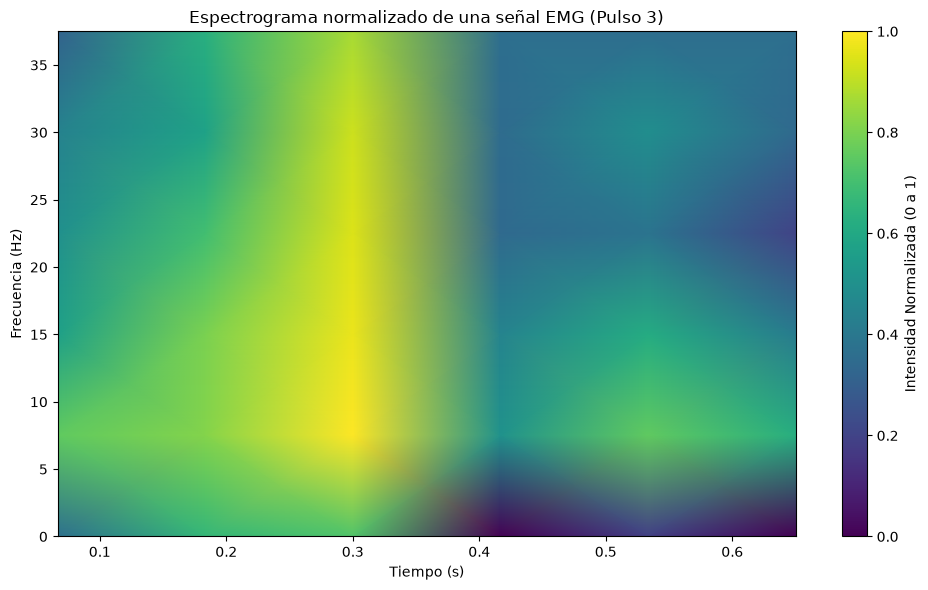

In [5]:
# 1. Cargar el registro (.dat + .hea)
ruta_registro = r'Data\Database\100'
record = wfdb.rdrecord(ruta_registro)

# 2. Extraer únicamente el Canal 0
voltaje_ch0 = record.p_signal[:, 0]

# 3. Cargar el CSV con los marcadores de tiempo
ruta_csv = r'Data\picos.csv'
df_picos = pd.read_csv(ruta_csv)

# 4. Definir qué latido queremos analizar
n = 3

# 5. Extraer la ventana asimétrica
ventana_ciclo = extraer_latido_asimetrico(voltaje_ch0, df_picos, indice_latido=n, fs=record.fs)

# 6. Generar el mapa de calor correctamente escalado
if ventana_ciclo is not None:
    print(f"Graficando latido {n}...")
    
    graficar_espectrograma_normalizado(
        ventana_ciclo, 
        fs=record.fs, 
        nperseg=48, 
        limite_hz=40,
        titulo=f'Espectrograma normalizado de una señal EMG (Pulso {n})'
    )